# 1.1 ResNet-50 features with LR and Gradient Boosting

Frozen ImageNet ResNet-50 features with logistic regression and gradient boosting, trained on all training images (casts and follow-ups included).

Steps:

1. Extract ResNet-50 features for all 20,327 images (cached).
2. Train logistic regression and gradient boosting with 5-fold cross-validation, for 2 seeds.
3. Score on the full test split, the clean subset (first visit, no cast), and no cast vs cast.

Input: `data/processed/` from `0.1_data-pipeline_fahim.ipynb`.

| Output | Contents |
|---|---|
| `data/interim/graz_resnet50_features.npy` | Features, float32, shape (20327, 2048), same row order as `graz.csv` |
| `models/resnet50_logreg_seed{seed}.joblib` | Trained logistic regression |
| `models/resnet50_histgb_seed{seed}.joblib` | Trained gradient boosting |
| `models/resnet50_baseline_predictions.csv` | Fracture probability of every model for every test image |

Feature extraction uses the GPU if there is one; the models train on CPU.

In [ ]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet50_Weights, resnet50

from snap.config import INTERIM_DATA_DIR, MODELS_DIR, PROCESSED_DATA_DIR

# Settings
SEEDS = [1337, 3407]
FEATURES_FILE = INTERIM_DATA_DIR / "graz_resnet50_features.npy"
GRID = {"lr": [0.00001, 0.0001, 0.001, 0.01, 0.1],
        "gb": [100, 200, 400]}
GRID_NAME = {"lr": "C", "gb": "trees"}
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Using", device)

Using cuda


## 1. Data

All images are used across the training, validation, and test sets.

In [ ]:
df = pd.read_csv(PROCESSED_DATA_DIR / "graz.csv")
labels = df["label"].values

train_rows = np.where(df["split"] == "train")[0]
val_rows = np.where(df["split"] == "val")[0]
test_rows = np.where(df["split"] == "test")[0]
print(f"train:       {len(train_rows)} ({labels[train_rows].mean():.0%} fracture)")
print(f"val:         {len(val_rows)} ({labels[val_rows].mean():.0%} fracture)")
print(f"full test:   {len(test_rows)} ({labels[test_rows].mean():.0%} fracture)")

train:       14182 (67% fracture)
val:         3202 (69% fracture)
full test:   2943 (65% fracture)


## 2. ResNet-50 features


Each image is encoded with an ImageNet-pretrained ResNet-50 (`IMAGENET1K_V2` weights). The backbone is frozen and its classification layer is removed. Global average pooling reduces each image to a 2,048-dimensional feature vector.

In [ ]:
class XrayDataset(Dataset):
    def __init__(self, images):
        self.images = images

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        image = torch.tensor(self.images[i], dtype=torch.float32) / 255  # (512, 256), values 0 to 1
        image = image.unsqueeze(0).repeat(3, 1, 1)                       # (3, 512, 256)
        for c in range(3):
            image[c] = (image[c] - IMAGENET_MEAN[c]) / IMAGENET_STD[c]
        return image


if not FEATURES_FILE.exists():
    images = np.load(PROCESSED_DATA_DIR / "graz_256x512_u8.npy", mmap_mode="r")
    loader = DataLoader(XrayDataset(images), batch_size=64, shuffle=False)

    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    model.fc = nn.Identity()  # drop the classifier; the output is now the 2,048 pooled features
    model = model.to(device)
    model.eval()

    all_features = []
    with torch.no_grad():
        for images_batch in loader:
            features = model(images_batch.to(device))
            all_features.append(features.cpu().numpy())
    np.save(FEATURES_FILE, np.concatenate(all_features).astype(np.float32))

X = np.load(FEATURES_FILE)
print("features:", X.shape)
assert X.shape == (len(df), 2048)

features: (20327, 2048)


## 3. Train with cross-validation

Settings are picked by 5-fold cross-validation on the training images, then refit on all training images.

- **Folds:** split by patient (`StratifiedGroupKFold`), so no child is in both parts, with the same fracture rate in each fold. The seed decides which patients go into which fold.
- **Logistic regression:** standardized features; `C` picked by mean CV AUC. It has no randomness, so both seeds give the same model.
- **Gradient boosting:** `HistGradientBoostingClassifier`; each split uses a random half of the features (`max_features=0.5`). The number of trees is picked by mean CV AUC.

The validation set is used only for the threshold. A model whose file already exists is loaded instead of retrained (no cross-validation then).

In [ ]:
def make_model(kind, setting, seed):
    if kind == "lr":
        return make_pipeline(StandardScaler(), LogisticRegression(C=setting, max_iter=2000, random_state=seed))
    else:
        return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=setting, early_stopping=False, max_features=0.5,
                                              random_state=seed)


def cross_validate(kind, setting, seed):
    X_train = X[train_rows]
    y_train = labels[train_rows]
    patients = df["patient_id"].values[train_rows]
    folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)

    fold_aucs = []
    for fold_train, fold_val in folds.split(X_train, y_train, groups=patients):
        model = make_model(kind, setting, seed)
        model.fit(X_train[fold_train], y_train[fold_train])
        probs = model.predict_proba(X_train[fold_val])[:, 1]
        fold_aucs.append(roc_auc_score(y_train[fold_val], probs))
    return fold_aucs


MODEL_FILE = {"lr": "resnet50_logreg_seed{}.joblib", "gb": "resnet50_histgb_seed{}.joblib"}


def train_model(kind, seed):
    path = MODELS_DIR / MODEL_FILE[kind].format(seed)
    if path.exists():
        print(f"{kind.upper()} seed {seed}: loading {path.name}")
        return joblib.load(path), None

    cv_rows = []
    for setting in GRID[kind]:
        fold_aucs = cross_validate(kind, setting, seed)
        cv_rows.append({"setting": setting, "cv_auc_mean": np.mean(fold_aucs), "cv_auc_std": np.std(fold_aucs)})
        print(f"{kind.upper()} seed {seed}  {GRID_NAME[kind]}={setting:<7}  CV AUC {np.mean(fold_aucs):.3f} ± {np.std(fold_aucs):.3f}")
    cv_table = pd.DataFrame(cv_rows)
    best_setting = cv_table.loc[cv_table["cv_auc_mean"].idxmax(), "setting"]
    if kind == "gb":
        best_setting = int(best_setting)

    # Refit the best setting on all training images
    model = make_model(kind, best_setting, seed)
    model.fit(X[train_rows], labels[train_rows])
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    joblib.dump(model, path)
    print(f"{kind.upper()} seed {seed}  best {GRID_NAME[kind]}={best_setting}  saved {path.name}")
    return model, cv_table


trained = {}    # (kind, seed) -> model
cv_tables = {}  # (kind, seed) -> CV table, only for models trained in this run
for seed in SEEDS:
    for kind in ["lr", "gb"]:
        model, cv_table = train_model(kind, seed)
        trained[(kind, seed)] = model
        if cv_table is not None:
            cv_tables[(kind, seed)] = cv_table
        val_auc = roc_auc_score(labels[val_rows], model.predict_proba(X[val_rows])[:, 1])
        print(f"{kind.upper()} seed {seed}  val AUC {val_auc:.3f}")

LR seed 1337  C=1e-05    CV AUC 0.838 ± 0.010


LR seed 1337  C=0.0001   CV AUC 0.884 ± 0.008


LR seed 1337  C=0.001    CV AUC 0.906 ± 0.008


LR seed 1337  C=0.01     CV AUC 0.900 ± 0.008


LR seed 1337  C=0.1      CV AUC 0.883 ± 0.007


LR seed 1337  best C=0.001  saved resnet50_logreg_seed1337.joblib
LR seed 1337  val AUC 0.911


... (10 outputs left out)

GB seed 3407  trees=100      CV AUC 0.893 ± 0.006


GB seed 3407  trees=200      CV AUC 0.902 ± 0.006


GB seed 3407  trees=400      CV AUC 0.908 ± 0.006


GB seed 3407  best trees=400  saved resnet50_histgb_seed3407.joblib
GB seed 3407  val AUC 0.909


In [ ]:
# Cross-validation AUC for every setting, averaged over the 2 seeds
for kind in ["lr", "gb"]:
    tables = [cv_tables[(kind, seed)] for seed in SEEDS if (kind, seed) in cv_tables]
    if len(tables) == 0:
        print(f"{kind.upper()}: models loaded from file, no cross-validation in this run")
        continue
    summary = pd.concat(tables).groupby("setting")[["cv_auc_mean", "cv_auc_std"]].mean().round(3)
    print(f"{kind.upper()}: {GRID_NAME[kind]}")
    display(summary)

LR: C


,cv_auc_mean,cv_auc_std
setting,,
0.00001,0.839,0.010
0.00010,0.884,0.008
0.00100,0.907,0.007
0.01000,0.901,0.006
0.10000,0.884,0.006


GB: trees


,cv_auc_mean,cv_auc_std
setting,,
100,0.893,0.008
200,0.902,0.007
400,0.907,0.007


### Save predictions

Fracture probability of every model and seed for every test image.

In [ ]:
predictions_df = df.loc[df["split"] == "test", ["filestem", "patient_id", "label", "cast", "clean", "split"]].copy()
for kind, name in [("lr", "logistic_regression"), ("gb", "gradient_boosting")]:
    for seed in SEEDS:
        predictions_df[f"{name}_seed{seed}"] = trained[(kind, seed)].predict_proba(X[test_rows])[:, 1]

predictions_path = MODELS_DIR / "resnet50_baseline_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)
print("Saved:", predictions_path.name, predictions_df.shape)

Saved: resnet50_baseline_predictions.csv (2943, 10)


### Learning curves

Log loss (left) and AUC (right) on the training and validation images as the models learn with one line per seed. Logistic regression is refit with 1 to 40 optimizer (L-BFGS) steps. Gradient boosting is scored after each new tree. If validation loss goes up while training loss goes down, the model is overfitting. Thinner lines are drawn on top, so overlapping seeds stay visible.

seed 1337  LR val loss 0.349, val AUC 0.911  |  GB val loss 0.354 (lowest 0.353 at tree 362), val AUC 0.906


seed 3407  LR val loss 0.349, val AUC 0.911  |  GB val loss 0.348 (lowest 0.348 at tree 369), val AUC 0.909


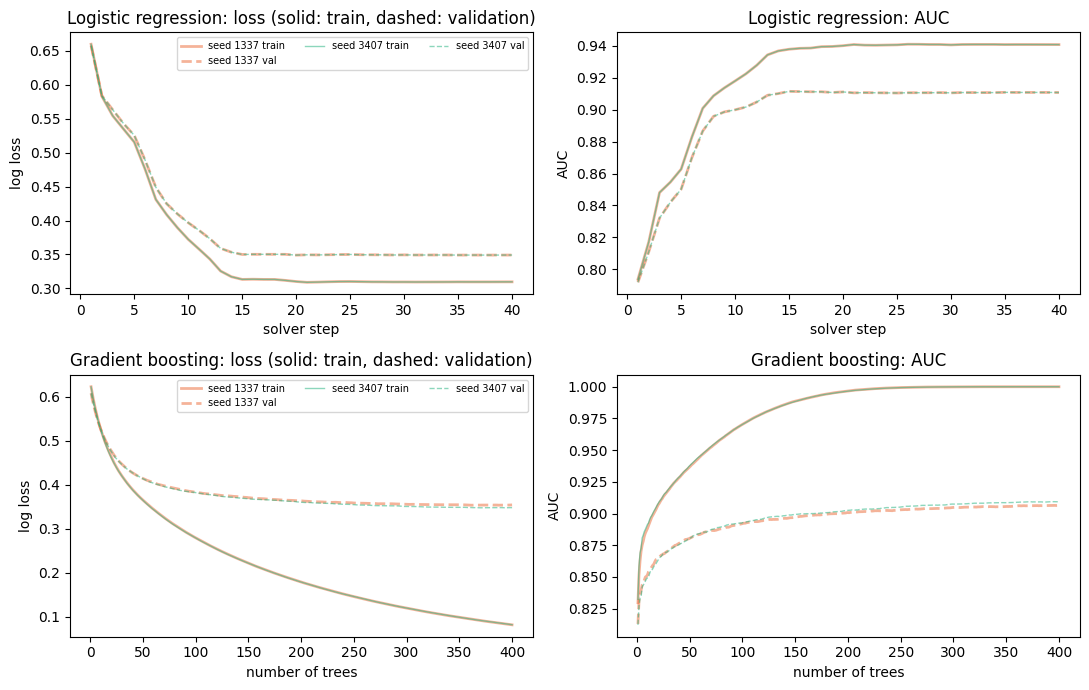

In [ ]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import log_loss

SEED_COLORS = {42: "#2a78d6", 1337: "#eb6834", 3407: "#1baf7a"}
SEED_WIDTHS = {42: 3, 1337: 2, 3407: 1}  # wide to thin, so identical curves still show every seed
steps = np.arange(1, 41)


def score(probs, rows):
    # Log loss and AUC of fracture probabilities for the given image rows
    return log_loss(labels[rows], probs), roc_auc_score(labels[rows], probs)


fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for seed in SEEDS:
    color = SEED_COLORS[seed]

    # Logistic regression: refit with more and more solver steps
    c_best = trained[("lr", seed)].named_steps["logisticregression"].C
    lr_curve = []  # one row per step: train loss, train AUC, val loss, val AUC
    for n_steps in steps:
        model = make_pipeline(StandardScaler(), LogisticRegression(C=c_best, max_iter=n_steps, random_state=seed))
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)  # stopping early on purpose
            model.fit(X[train_rows], labels[train_rows])
        train_scores = score(model.predict_proba(X[train_rows])[:, 1], train_rows)
        val_scores = score(model.predict_proba(X[val_rows])[:, 1], val_rows)
        lr_curve.append(train_scores + val_scores)
    lr_curve = np.array(lr_curve)

    # Gradient boosting: scores after each tree of the saved model
    gb_model = trained[("gb", seed)]
    gb_train = [score(probs[:, 1], train_rows) for probs in gb_model.staged_predict_proba(X[train_rows])]
    gb_val = [score(probs[:, 1], val_rows) for probs in gb_model.staged_predict_proba(X[val_rows])]
    gb_curve = np.hstack([np.array(gb_train), np.array(gb_val)])
    trees = np.arange(1, len(gb_curve) + 1)

    for row, (x, curve) in enumerate([(steps, lr_curve), (trees, gb_curve)]):
        for col in [0, 1]:  # 0: loss, 1: AUC
            axes[row, col].plot(x, curve[:, col], color=color, linewidth=SEED_WIDTHS[seed], alpha=0.5, label=f"seed {seed} train")
            axes[row, col].plot(x, curve[:, col + 2], color=color, linewidth=SEED_WIDTHS[seed], alpha=0.5, linestyle="--", label=f"seed {seed} val")
    print(f"seed {seed}  LR val loss {lr_curve[-1, 2]:.3f}, val AUC {lr_curve[-1, 3]:.3f}"
          f"  |  GB val loss {gb_curve[-1, 2]:.3f} (lowest {gb_curve[:, 2].min():.3f} at tree {trees[np.argmin(gb_curve[:, 2])]}),"
          f" val AUC {gb_curve[-1, 3]:.3f}")

for row, (model_label, xlabel) in enumerate([("Logistic regression", "solver step"), ("Gradient boosting", "number of trees")]):
    axes[row, 0].set(xlabel=xlabel, ylabel="log loss", title=f"{model_label}: loss (solid: train, dashed: validation)")
    axes[row, 1].set(xlabel=xlabel, ylabel="AUC", title=f"{model_label}: AUC")
    axes[row, 0].legend(fontsize=7, ncol=3)
plt.tight_layout()
plt.show()

## 4. Results

- **AUC** is the main metric.
- **Sensitivity and specificity** use one threshold per model and seed
- **Test sets:** full, clean (first visit, no cast), no cast, cast.
- **Uncertainty:** mean ± std over the 2 seeds and a patient-level bootstrap 95% interval (1,000 resamples of test patients).

In [ ]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
MODELS = {"lr": "Logistic regression", "gb": "Gradient boosting"}
MODEL_COLORS = {"lr": BLUE, "gb": ORANGE}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100})

test = df[df["split"] == "test"].copy()

# One threshold per model and seed from the validation set; each model/seed's test probabilities as a column
thresholds = {}
for model_name in MODELS:
    for seed in SEEDS:
        model = trained[(model_name, seed)]
        fpr, tpr, thr = roc_curve(labels[val_rows], model.predict_proba(X[val_rows])[:, 1])
        thresholds[(model_name, seed)] = thr[np.argmax(tpr - fpr)]
        test[f"prob_{model_name}_{seed}"] = model.predict_proba(X[test_rows])[:, 1]
    test[f"prob_{model_name}_mean"] = test[[f"prob_{model_name}_{seed}" for seed in SEEDS]].mean(axis=1)

SUBGROUPS = {
    "Full test": test["label"] >= 0,
    "Clean test": test["clean"] == 1,
    "No cast": test["cast"] == 0,
    "Cast": test["cast"] == 1,
}
METRICS = ["AUC", "sensitivity", "specificity"]

In [ ]:
def metrics(y, probs, threshold):
    predicted = probs >= threshold
    auc = roc_auc_score(y, probs)
    sensitivity = predicted[y == 1].mean()      # share of fractures found
    specificity = (~predicted[y == 0]).mean()   # share of normal wrists called normal
    return auc, sensitivity, specificity


def seed_metrics(part, model_name):
    # One row per seed: AUC, sensitivity, specificity
    rows = []
    for seed in SEEDS:
        probs = part[f"prob_{model_name}_{seed}"].values
        rows.append(metrics(part["label"].values, probs, thresholds[(model_name, seed)]))
    return np.array(rows)


def bootstrap_ci(part, model_name, n_boot=1000):
    rng = np.random.default_rng(0)
    rows_of_patient = part.groupby("patient_id").indices  # patient id -> row positions in part
    patients = list(rows_of_patient.keys())
    samples = []
    for _ in range(n_boot):
        chosen = rng.choice(patients, size=len(patients), replace=True)
        rows = np.concatenate([rows_of_patient[p] for p in chosen])
        resample = part.iloc[rows]
        if resample["label"].nunique() < 2:
            continue  # AUC needs both classes
        samples.append(seed_metrics(resample, model_name).mean(axis=0))
    return np.percentile(samples, [2.5, 97.5], axis=0)  # row 0: lower bound, row 1: upper bound


table = []
for model_name in MODELS:
    for name, mask in SUBGROUPS.items():
        part = test[mask]
        per_seed = seed_metrics(part, model_name)
        ci = bootstrap_ci(part, model_name)
        row = {"model": MODELS[model_name], "subgroup": name, "images": len(part),
               "normal": int((part["label"] == 0).sum()), "fracture %": 100 * part["label"].mean()}
        for j, metric in enumerate(METRICS):
            row[metric] = per_seed[:, j].mean()
            row[metric + " std"] = per_seed[:, j].std(ddof=1)
            row[metric + " low"] = ci[0, j]
            row[metric + " high"] = ci[1, j]
        table.append(row)
table = pd.DataFrame(table).set_index(["model", "subgroup"])

shown = table[["images", "normal", "fracture %"]].round(0).astype(int)
for metric in METRICS:
    shown[metric] = [f"{r[metric]:.3f} ± {r[metric + ' std']:.3f}  [{r[metric + ' low']:.3f}, {r[metric + ' high']:.3f}]"
                     for _, r in table.iterrows()]
print("mean ± std over seeds  [patient-level bootstrap 95% interval]")
display(shown)
for model_name, model_label in MODELS.items():
    gap = table.loc[(model_label, "Full test"), "AUC"] - table.loc[(model_label, "Clean test"), "AUC"]
    print(f"{model_label}: shortcut gap (full - clean AUC) {gap:.3f}")

mean ± std over seeds  [patient-level bootstrap 95% interval]


images  normal  fracture %  \
model               subgroup                                 
Logistic regression Full test     2943    1044          65   
                    Clean test    1637     987          40   
                    No cast       2124    1013          52   
                    Cast           819      31          96   
Gradient boosting   Full test     2943    1044          65   
                    Clean test    1637     987          40   
                    No cast       2124    1013          52   
                    Cast           819      31          96   

                                                          AUC  \
model               subgroup                                    
Logistic regression Full test   0.918 ± 0.000  [0.904, 0.931]   
                    Clean test  0.861 ± 0.000  [0.840, 0.882]   
                    No cast     0.890 ± 0.000  [0.873, 0.906]   
                    Cast        0.645 ± 0.000  [0.575, 0.721]   
Gradient boosting   Full test   0.918 ± 0.000  [0.904, 0.931]   
                    Clean test  0.863 ± 0.000  [0.843, 0.883]   
                    No cast     0.889 ± 0.000  [0.872, 0.905]   
                    Cast        0.665 ± 0.028  [0.596, 0.752]   

                                                  sensitivity  \
model               subgroup                                    
Logistic regression Full test   0.838 ± 0.000  [0.815, 0.860]   
                    Clean test  0.631 ± 0.000  [0.590, 0.671]   
                    No cast     0.727 ± 0.000  [0.697, 0.762]   
                    Cast        0.995 ± 0.000  [0.989, 0.999]   
Gradient boosting   Full test   0.832 ± 0.009  [0.809, 0.854]   
                    Clean test  0.636 ± 0.014  [0.597, 0.672]   
                    No cast     0.713 ± 0.015  [0.682, 0.745]   
                    Cast        1.000 ± 0.000  [1.000, 1.000]   

                                                  specificity  
model               subgroup                                   
Logistic regression Full test   0.857 ± 0.000  [0.834, 0.880]  
                    Clean test  0.887 ± 0.000  [0.866, 0.907]  
                    No cast     0.884 ± 0.000  [0.864, 0.904]  
                    Cast        0.000 ± 0.000  [0.000, 0.000]  
Gradient boosting   Full test   0.873 ± 0.002  [0.850, 0.894]  
                    Clean test  0.904 ± 0.003  [0.886, 0.922]  
                    No cast     0.900 ± 0.002  [0.882, 0.917]  
                    Cast        0.000 ± 0.000  [0.000, 0.000]

Logistic regression: shortcut gap (full - clean AUC) 0.057
Gradient boosting: shortcut gap (full - clean AUC) 0.056


### ROC curves

Mean probability over the 2 seeds. Solid: full test, dashed: clean test.

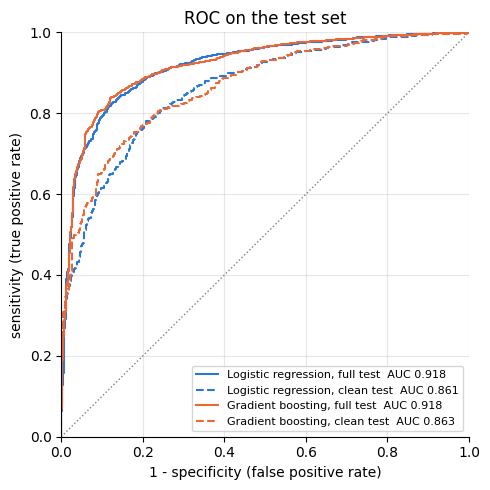

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
for model_name, model_label in MODELS.items():
    for name, style in [("Full test", "-"), ("Clean test", "--")]:
        part = test[SUBGROUPS[name]]
        fpr, tpr, _ = roc_curve(part["label"], part[f"prob_{model_name}_mean"])
        auc = table.loc[(model_label, name), "AUC"]
        ax.plot(fpr, tpr, color=MODEL_COLORS[model_name], linestyle=style, linewidth=1.5,
                label=f"{model_label}, {name.lower()}  AUC {auc:.3f}")
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", linewidth=1)
ax.set(xlabel="1 - specificity (false positive rate)", ylabel="sensitivity (true positive rate)",
       title="ROC on the test set", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### Predicted probabilities

Mean probability over the 2 seeds, split by cast. Dashed line: mean validation threshold.
If the model uses the cast, normal wrists in a cast get high probabilities.

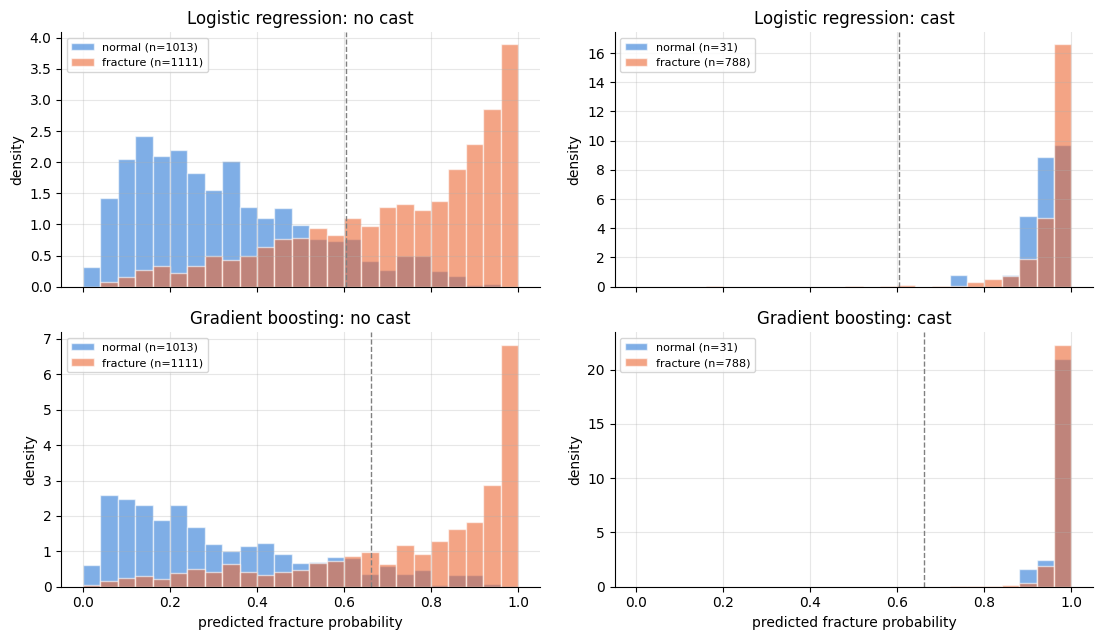

In [ ]:
bins = np.linspace(0, 1, 26)
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for row, (model_name, model_label) in enumerate(MODELS.items()):
    mean_threshold = np.mean([thresholds[(model_name, seed)] for seed in SEEDS])
    for col, (name, cast_value) in enumerate([("No cast", 0), ("Cast", 1)]):
        ax = axes[row, col]
        part = test[test["cast"] == cast_value]
        for label_value, label_name, color in [(0, "normal", BLUE), (1, "fracture", ORANGE)]:
            probs = part.loc[part["label"] == label_value, f"prob_{model_name}_mean"]
            ax.hist(probs, bins=bins, density=True, alpha=0.6, color=color, edgecolor="white",
                    label=f"{label_name} (n={len(probs)})")
        ax.axvline(mean_threshold, color="grey", linestyle="--", linewidth=1)
        ax.set(title=f"{model_label}: {name.lower()}", ylabel="density")
        ax.legend(fontsize=8)
axes[1, 0].set_xlabel("predicted fracture probability")
axes[1, 1].set_xlabel("predicted fracture probability")
plt.tight_layout()
plt.show()

### Confusion matrices

Each row shows how the images of a true class are distributed across the predicted classes. Values are averaged over the 2 seeds, with each seed evaluated at its own validation-selected threshold.

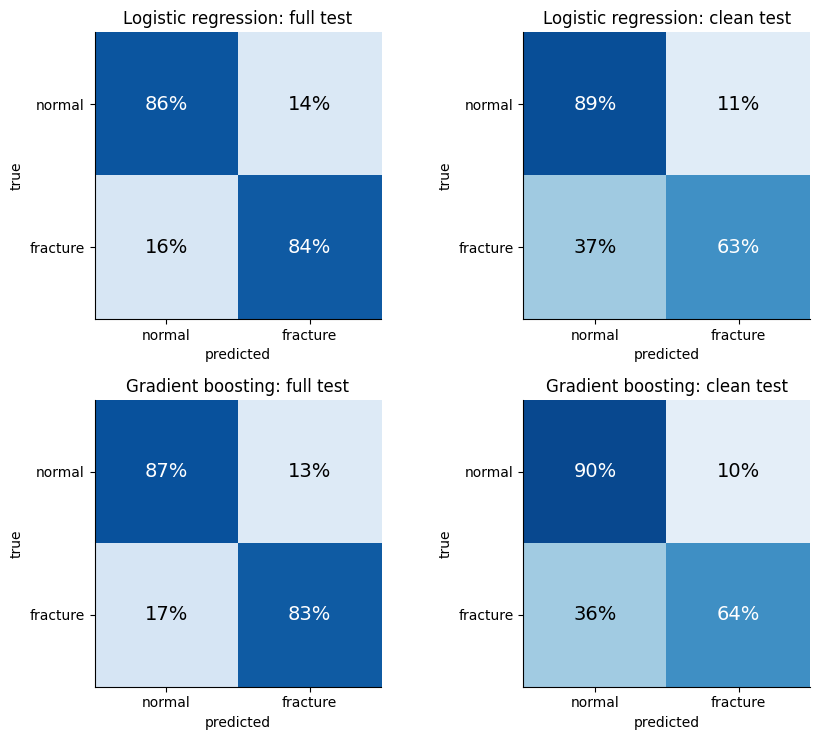

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7.5))
for row, (model_name, model_label) in enumerate(MODELS.items()):
    for col, name in enumerate(["Full test", "Clean test"]):
        ax = axes[row, col]
        part = test[SUBGROUPS[name]]
        matrix = np.zeros((2, 2))
        for seed in SEEDS:
            predicted = (part[f"prob_{model_name}_{seed}"] >= thresholds[(model_name, seed)]).astype(int)
            for true_value in [0, 1]:
                for pred_value in [0, 1]:
                    matrix[true_value, pred_value] += ((part["label"] == true_value) & (predicted == pred_value)).sum()
        row_share = matrix / matrix.sum(axis=1, keepdims=True)
        ax.imshow(row_share, cmap="Blues", vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                color = "white" if row_share[i, j] > 0.5 else "black"
                ax.text(j, i, f"{row_share[i, j]:.0%}", ha="center", va="center", color=color, fontsize=14)
        ax.set_xticks([0, 1], ["normal", "fracture"])
        ax.set_yticks([0, 1], ["normal", "fracture"])
        ax.set(xlabel="predicted", ylabel="true", title=f"{model_label}: {name.lower()}")
        ax.grid(False)
plt.tight_layout()
plt.show()

## 5. Findings

Results are reported as the mean ± std over 2 seeds with a patient-level bootstrap 95% interval in brackets.

* **Cross-validation:** Both seeds select C=0.001 for logistic regression (LR) and 400 trees for gradient boosting (GB). Both models reach a CV AUC of 0.907.
* **Test AUC:** On the full test set, both models score 0.918. On the clean subset (no casts), AUC drops to 0.861 for LR and 0.863 for GB. This gap of about 0.06 suggests the models rely on a shortcut.
* **Casts:** All 31 normal wrists in a cast are predicted as fractures while sensitivity on cast images is 0.995-1.00. The models appear to treat the cast itself as a sign of fracture. Within cast images, AUC is low (LR 0.65, GB 0.67), so the models cannot separate fractures from normal wrists once a cast is present.
* **Seeds:** LR gives identical results across seeds. GB varies mainly on cast images (AUC ± 0.03).
* **Learning curves:** LR converges within about 15 steps (validation loss 0.349). GB fits the training set perfectly, but its validation loss reaches a minimum near tree 365 and then plateaus, so 400 trees is sufficient.